# 05 · Closing the loop: mirror, controller, delay and noise

This notebook connects the pieces into an AO loop with `ao_closed_loop.py`: a deformable mirror with Gaussian influence functions, an interaction matrix, a TSVD reconstructor and an integrator with optional command leak, driven by frozen-flow turbulence.

**Checks against theory:** the mirror's fitting floor against $\kappa\,(d/r_0)^{5/3}$, and the characteristic roots against the integrator stability limit $g_{\max}(d) = 2\sin\!\big(\pi / (2(2d+1))\big)$ for $d$ frames of delay.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIGURES = ROOT / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from ao_closed_loop import (
    actuator_centers_on_pupil,
    build_dm_wfs_response_matrix,
    fit_dm_to_phase,
    gaussian_influence_functions,
    run_closed_loop_ao,
    tsvd_reconstructor,
)
from phase_screen import fourier_phase_screen, frozen_flow_shift, scale_r0_with_wavelength
from reconstruction import measure_slopes, subaperture_masks
from zernike import make_pupil_grid

## 1. The system

A 1 m pupil with 10 × 10 lenslets and an actuator grid on the lenslet corners (Fried geometry, 10 cm pitch). Actuators are kept out to 1.15 pupil radii, a guard ring just outside the pupil; section 2 shows why. Each actuator pushes a Gaussian bump of width $0.55\times$ the pitch, so a poked actuator moves its neighbour by about 19%, typical of a continuous face-sheet mirror. A command is the phase the actuator adds at its own centre. The wavefront sensor works at 700 nm, where $r_0 = 0.15$ m ($r_0 = 0.10$ m at 500 nm). A 8.3 m/s wind moves the turbulence by one sample (8.3 mm) per frame at 1 kHz.

101 actuators (pitch 10 cm, guard ring to 1.15 R); 79 sub-apertures; r0 at 700 nm = 0.150 m
Neighbour coupling: 19%;  wind 8.3 m/s
Interaction matrix (158, 101): kept 98 of 101 singular values (smallest/largest = 4.9e-03)


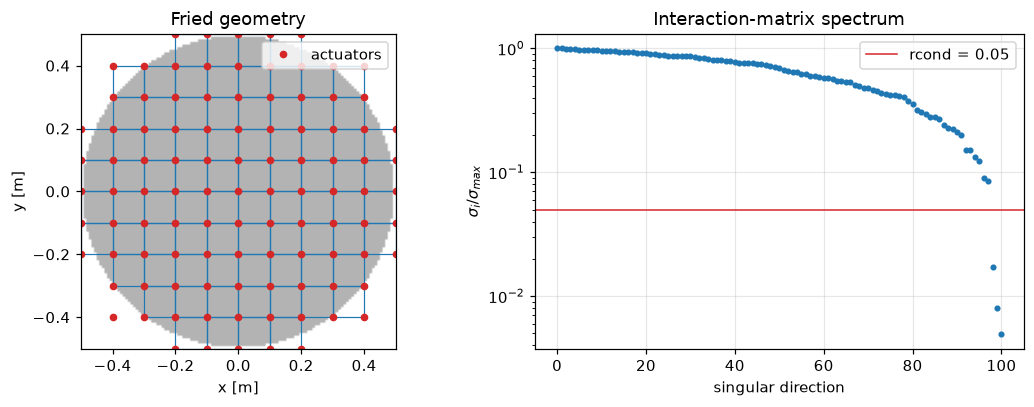

In [2]:
D, N_LENSLETS, N_ACT, COUPLING = 1.0, 10, 11, 0.55
X, Y, rho, theta, pupil, DELTA = make_pupil_grid(N=121, diameter=D)   # 8.3 mm samples
R0_WFS = scale_r0_with_wavelength(0.10, 700e-9)
FRAME_RATE = 1000.0
L0 = 25.0

GUARD = 1.15
act_centers, pitch = actuator_centers_on_pupil(D, N_ACT, radius_factor=GUARD)
influence = gaussian_influence_functions(X, Y, pupil, act_centers, pitch, coupling=COUPLING, normalize_peak=False)
lens_centers, lens_masks = subaperture_masks(X, Y, pupil, n_lenslets=N_LENSLETS, min_fill=0.5)
print(f"{len(act_centers)} actuators (pitch {pitch * 100:.0f} cm, guard ring to {GUARD} R); {len(lens_masks)} sub-apertures; r0 at 700 nm = {R0_WFS:.3f} m")
print(f"Neighbour coupling: {np.exp(-1 / (2 * COUPLING**2)):.0%};  wind {DELTA * FRAME_RATE:.1f} m/s")

A, _ = build_dm_wfs_response_matrix(influence, pupil, X, Y, n_lenslets=N_LENSLETS, min_fill=0.5)
RCOND = 0.05
R, S, kept = tsvd_reconstructor(A, rcond=RCOND)
print(f"Interaction matrix {A.shape}: kept {kept} of {len(S)} singular values (smallest/largest = {S[-1] / S[0]:.1e})")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].imshow(pupil, origin="lower", cmap="Greys", alpha=0.3, extent=[-D / 2, D / 2, -D / 2, D / 2])
size = D / N_LENSLETS
for cx, cy in lens_centers:
    axes[0].add_patch(plt.Rectangle((cx - size / 2, cy - size / 2), size, size, fill=False, color="C0", lw=0.8))
axes[0].plot(act_centers[:, 0], act_centers[:, 1], "o", color="C3", ms=4, label="actuators")
axes[0].set(title="Fried geometry", xlabel="x [m]", ylabel="y [m]")
axes[0].legend(loc="upper right")
axes[0].grid(False)
axes[1].semilogy(S / S[0], ".")
axes[1].axhline(RCOND, color="C3", lw=1, label=f"rcond = {RCOND}")
axes[1].set(xlabel="singular direction", ylabel=r"$\sigma_i/\sigma_{max}$", title="Interaction-matrix spectrum")
axes[1].legend()
plt.tight_layout()
plt.show()

The smallest singular values belong to guard-ring actuators, which the sensor only sees through the edge of their bumps inside the pupil. The cutoff drops the few combinations it cannot measure reliably.

## 2. Check: the fitting floor, and why the guard ring matters

Even a perfect sensor and controller leave what the mirror cannot shape. `fit_dm_to_phase` finds the best least-squares mirror shape for a phase map, and the classical fitting-error scaling ([Hudgin 1977](https://doi.org/10.1364/JOSA.67.000393)) is $\sigma^2_{\mathrm{fit}} = \kappa\,(d/r_0)^{5/3}$ with $d$ the actuator pitch. The coefficient $\kappa$ depends on the influence functions and actuator geometry; 0.28 is used here as a conventional reference value rather than an exact prediction for this Gaussian mirror.

The table compares this mirror with one that keeps only the actuators inside the pupil, using ten turbulence frames. Besides the fitting floor it shows the one-shot reconstruction error: the residual after measuring the frame with the sensor and applying $R\,\mathbf{s}$ once, which is what a converged loop on frozen turbulence would leave.

In [3]:
N_STEPS = 300
to_nm = 700 / (2 * np.pi)
sheet, *_ = fourier_phase_screen(N=768, delta=DELTA, r0=R0_WFS, L0=L0, diameter=None, seed=11)
frames = [frozen_flow_shift(sheet, shift, 0, mask=pupil) for shift in range(0, N_STEPS, 30)]


def floors(influence_functions, reconstructor):
    fit, one_shot = [], []
    for phase in frames:
        _, _, residual = fit_dm_to_phase(phase, influence_functions, pupil)
        fit.append(np.nanvar(residual[pupil]))
        _, slopes = measure_slopes(phase, pupil, X, Y, centers=lens_centers, masks=lens_masks)
        correction = np.tensordot(reconstructor @ slopes.reshape(-1), np.nan_to_num(influence_functions), axes=1)
        left = phase[pupil] - correction[pupil]
        one_shot.append(np.var(left))
    return np.mean(fit), np.mean(one_shot)


inner_centers, _ = actuator_centers_on_pupil(D, N_ACT)
inner = gaussian_influence_functions(X, Y, pupil, inner_centers, pitch, coupling=COUPLING, normalize_peak=False)
A_inner, _ = build_dm_wfs_response_matrix(inner, pupil, X, Y, n_lenslets=N_LENSLETS, min_fill=0.5)
R_inner, _, _ = tsvd_reconstructor(A_inner, rcond=RCOND)

print("mirror                     actuators   fitting floor   one-shot reconstruction   kappa")
for label, infl, rec in [("inside the pupil only", inner, R_inner), (f"guard ring to {GUARD} R", influence, R)]:
    fit_var, one_shot_var = floors(infl, rec)
    print(f"{label:26s} {len(infl):9d} {np.sqrt(fit_var) * to_nm:12.0f} nm {np.sqrt(one_shot_var) * to_nm:20.0f} nm {fit_var / (pitch / R0_WFS) ** (5 / 3):10.2f}")
fit_rms = np.sqrt(fit_var)
print(f"\nTextbook kappa = 0.28 gives {np.sqrt(0.28 * (pitch / R0_WFS) ** (5 / 3)) * to_nm:.0f} nm for d = {pitch * 100:.0f} cm and r0 = {R0_WFS * 100:.0f} cm")

mirror                     actuators   fitting floor   one-shot reconstruction   kappa


inside the pupil only             81           62 nm                  170 nm       0.61


guard ring to 1.15 R             101           38 nm                   43 nm       0.23

Textbook kappa = 0.28 gives 42 nm for d = 10 cm and r0 = 15 cm


## 3. The closed loop

Every frame the sensor measures the residual seen by the science camera, the reconstructor turns the slopes into a command increment, and the integrator updates the mirror for a later frame:

$$\mathbf{c}_{k+1} = (1-\ell)\,\mathbf{c}_k + g\,R\,\mathbf{s}_{k-d}.$$

Here $g = 0.4$ and the update uses the preceding frame’s measurement ($d = 1$) to set the mirror for the next frame. This represents an additional frame of delay beyond the current measurement-to-next-frame update, with no model of detector exposure or readout.

Open loop   2.27 rad = 253 nm
Closed loop 0.47 rad = 53 nm  (fitting floor 38 nm)
H-band Strehl (Maréchal): 0.96 closed loop, 0.394 open loop


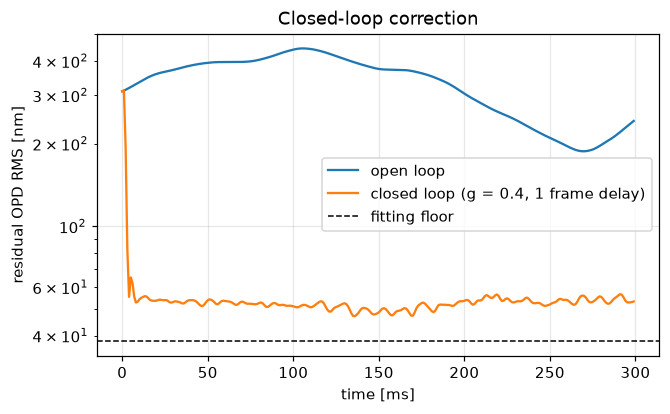

In [4]:
loop = dict(n_lenslets=N_LENSLETS, min_fill=0.5, reconstructor=R, compute_strehl=False, wind_shift_per_step=(1, 0))
history = run_closed_loop_ao(sheet, pupil, X, Y, influence, A, n_steps=N_STEPS, gain=0.4, delay_frames=1, **loop)

time_ms = np.arange(N_STEPS) / FRAME_RATE * 1e3
tail = slice(N_STEPS // 2, None)
closed = np.median(history["rms_before"][tail])
opened = np.median(history["rms_atmosphere"][tail])
print(f"Open loop   {opened:.2f} rad = {opened * to_nm:.0f} nm")
print(f"Closed loop {closed:.2f} rad = {closed * to_nm:.0f} nm  (fitting floor {fit_rms * to_nm:.0f} nm)")
print(f"H-band Strehl (Maréchal): {np.exp(-(closed * 700 / 1650) ** 2):.2f} closed loop, {np.exp(-(opened * 700 / 1650) ** 2):.3f} open loop")

fig, ax = plt.subplots(figsize=(6.6, 3.8))
ax.semilogy(time_ms, history["rms_atmosphere"] * to_nm, label="open loop")
ax.semilogy(time_ms, history["rms_before"] * to_nm, label="closed loop (g = 0.4, 1 frame delay)")
ax.axhline(fit_rms * to_nm, color="k", ls="--", lw=1, label="fitting floor")
ax.set(xlabel="time [ms]", ylabel="residual OPD RMS [nm]", title="Closed-loop correction")
ax.legend()
plt.show()

## 4. Check: delay and the stability limit

For a pure integrator with no command leak, each retained controllable mode obeys $e_{k+1} = e_k - g\,e_{k-d}$. Its characteristic polynomial is

$$p(z) = z^{d+1} - z^d + g.$$

Asymptotic stability requires every root to lie strictly inside the unit circle. At the first crossing, $z = e^{i\omega}$ gives $g = z^d(1-z)$; requiring real positive $g$ gives $\omega = \pi/(2d+1)$ and

$$0 < g < g_{\max}(d) = 2\sin\!\big(\pi/(2(2d+1))\big).$$

The upper limits are 2, 1, 0.62 and 0.45 for $d = 0$ to 3. Equality is marginal, with non-decaying oscillations, rather than asymptotic stability. The root calculation below checks the formula independently. The heatmap shows a different quantity: the median residual in the second half of 150-frame turbulence runs, relative to open loop. A short run can improve that residual even on a marginal boundary.

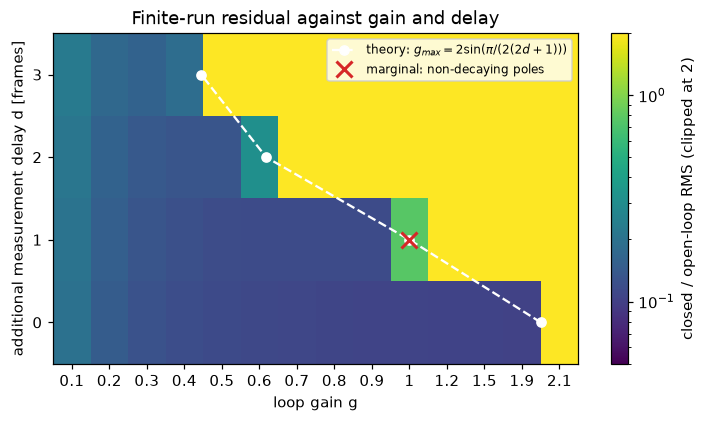

d = 0: theory g_max = 2.00; largest asymptotically stable tested gain = 1.9; largest gain with closed < open in this finite scan = 1.9; best ratio 0.104 at g = 1.9
d = 1: theory g_max = 1.00; largest asymptotically stable tested gain = 0.9; largest gain with closed < open in this finite scan = 1.0; best ratio 0.115 at g = 0.8
d = 2: theory g_max = 0.62; largest asymptotically stable tested gain = 0.6; largest gain with closed < open in this finite scan = 0.6; best ratio 0.132 at g = 0.5
d = 3: theory g_max = 0.45; largest asymptotically stable tested gain = 0.4; largest gain with closed < open in this finite scan = 0.4; best ratio 0.159 at g = 0.3
d = 1, g = 1: pole radius 1.000000, marginal; finite-run closed/open ratio 0.771


In [5]:
gains = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.2, 1.5, 1.9, 2.1])
delays = np.arange(4)
ratio = np.zeros((len(delays), len(gains)))
for i, d in enumerate(delays):
    for j, g in enumerate(gains):
        h = run_closed_loop_ao(sheet, pupil, X, Y, influence, A, n_steps=150, gain=g, delay_frames=d, **loop)
        ratio[i, j] = np.median(h["rms_before"][75:]) / np.median(h["rms_atmosphere"][75:])


def integrator_pole_radius(gain, delay):
    # z^(d+1) - z^d + g; for d = 0 the last coefficient is g - 1.
    coefficients = np.zeros(delay + 2)
    coefficients[0] = 1.0
    coefficients[1] = -1.0
    coefficients[-1] += gain
    return np.max(np.abs(np.roots(coefficients)))


g_max = 2 * np.sin(np.pi / (2 * (2 * delays + 1)))
pole_radius = np.array([[integrator_pole_radius(g, d) for g in gains] for d in delays])
stable = pole_radius < 1.0 - 1e-10
marginal = np.abs(pole_radius - 1.0) <= 1e-10
assert np.array_equal(stable, gains[None, :] < g_max[:, None] - 1e-10)

fig, ax = plt.subplots(figsize=(7.7, 3.9))
image = ax.imshow(np.clip(ratio, 0.05, 2.0), origin="lower", aspect="auto", cmap="viridis",
                  norm=plt.matplotlib.colors.LogNorm(vmin=0.05, vmax=2.0), extent=[-0.5, len(gains) - 0.5, -0.5, len(delays) - 0.5])
fig.colorbar(image, ax=ax, label="closed / open-loop RMS (clipped at 2)")
ax.plot(np.interp(g_max, gains, np.arange(len(gains))), delays, "w--o", label=r"theory: $g_{max} = 2\sin(\pi/(2(2d+1)))$")
marginal_rows, marginal_columns = np.nonzero(marginal)
ax.plot(marginal_columns, marginal_rows, "x", color="C3", ms=10, mew=2, label="marginal: non-decaying poles")
ax.set_xticks(range(len(gains)), [f"{g:g}" for g in gains])
ax.set_yticks(delays)
ax.set(xlabel="loop gain g", ylabel="additional measurement delay d [frames]", title="Finite-run residual against gain and delay")
ax.legend(loc="upper right", fontsize=8)
ax.grid(False)
fig.savefig(FIGURES / "05_gain_delay.png", dpi=150, bbox_inches="tight")
plt.show()

for d, limit, row, is_stable in zip(delays, g_max, ratio, stable):
    print(f"d = {d}: theory g_max = {limit:.2f}; largest asymptotically stable tested gain = {gains[is_stable].max():.1f}; "
          f"largest gain with closed < open in this finite scan = {gains[row < 1.0].max():.1f}; "
          f"best ratio {row.min():.3f} at g = {gains[np.argmin(row)]:g}")
j_boundary = int(np.flatnonzero(gains == 1.0)[0])
print(f"d = 1, g = 1: pole radius {pole_radius[1, j_boundary]:.6f}, marginal; "
      f"finite-run closed/open ratio {ratio[1, j_boundary]:.3f}")

## 5. Noise and the best gain

A higher gain follows the turbulence faster (less servo-lag error) but also passes more measurement noise to the mirror. With noisy slopes the best gain therefore moves down. The noise levels below are multiples of the RMS slope that the closed loop itself measures.

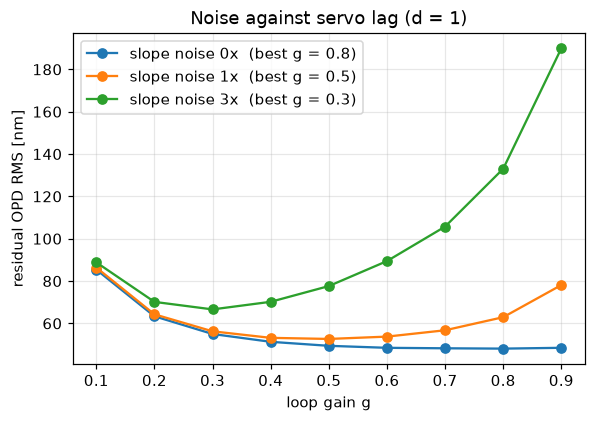

In [6]:
typical_slope = np.std(measure_slopes(frozen_flow_shift(sheet, 0, 0, mask=pupil), pupil, X, Y, centers=lens_centers, masks=lens_masks)[1]) * closed / opened
noise_gains = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
fig, ax = plt.subplots(figsize=(6, 3.9))
for factor in [0.0, 1.0, 3.0]:
    tail_rms = []
    for g in noise_gains:
        h = run_closed_loop_ao(sheet, pupil, X, Y, influence, A, n_steps=150, gain=g, delay_frames=1,
                               slope_noise_std=factor * typical_slope, seed=3, **loop)
        tail_rms.append(np.median(h["rms_before"][75:]) * to_nm)
    best = noise_gains[int(np.argmin(tail_rms))]
    ax.plot(noise_gains, tail_rms, "o-", label=f"slope noise {factor:g}x  (best g = {best:g})")
ax.set(xlabel="loop gain g", ylabel="residual OPD RMS [nm]", title="Noise against servo lag (d = 1)")
ax.legend()
plt.show()

## Summary

- The guard ring matters: with actuators only inside the pupil the sensor cannot drive the edge, and one measurement-and-correction leaves 170 nm. With actuators out to 1.15 pupil radii the fitting floor is 38 nm ($\kappa = 0.23$, close to the conventional reference value) and one correction leaves 43 nm.
- With gain 0.4 and one frame of delay the loop takes 253 nm down to 53 nm (H-band Strehl 0.39 → 0.96 by Maréchal). The 37 nm above the floor, in quadrature, is servo lag and aliasing.
- The characteristic roots reproduce the strict integrator stability limits: the largest asymptotically stable tested gains are 1.9, 0.9, 0.6 and 0.4 for $d$ = 0 to 3. At $d = 1$, $g = 1$ has unit-modulus poles and sustained oscillations, even though it improves the residual in this finite turbulence scan.
- Delay costs performance even when the loop is stable: the best residual rises from 0.10 to 0.16 of open loop between $d = 0$ and $d = 3$. Slope noise moves the best gain down, from 0.8 without noise to 0.5 and 0.3 with 1× and 3× noise.